# AP 155 Lab Exercise
---
## Exercise 12: More Integration

_Instructions_: 
- **Problem 1**: Figure: Diffraction Pattern, discussion: Explain the figure
- **Problem 2**: Figure: Gamma Function, discussion: *What is the difference between this version of Monte Carlo and the one we did in the previous session? What should we be careful of when applying Monte Carlo with Importance sampling?*
- **Code**: Complete the code and ensure it is functional, error-free, readable, and efficient (where needed). Include concise Markdown documentation highlighting the critical steps of your algorithm for each problem.

### Student Information
- _Full Name (Last Name, First Name)_: Iniego, Angel Nicole
- _Student No._: 2024-09622
- _Section_: THR-TX-X

### Grading Information (c/o Lab Instructor)
- [Rubrics description link](https://drive.google.com/file/d/1BMSlPot2Mc7XLu0eo4S8I8gLBsIadbCL/view)

| Criteria | Score | Subtotal |
| --- | --- | --- |
| Report figure | XX | 20 |
| Report discussion | XX | 20|
| Code readability | XX | 20 |
| Code efficiency | XX | 20 | 
| Code appropriateness  | XX | 20 | 
| **TOTAL** | XXX | 100 |

_Date and Time Scored (MM/DD/YYYY HH:MM AM/PM):_ 

---
## Section 1: Report

### Report figure

**Figure 1. Bessel Function.** 
<img src="../Figures/012_Bessel.png" alt="Combined Plots for phi(x) and f(x)." width=100% caption="Combined Plots">

**Figure 2. Diffraction Pattern.** 
<img src="../Figures/012_DiffractionPattern.png" alt="Combined Plots for phi(x) and f(x)." width=100% caption="Combined Plots">

**Figure 3. Gamma Function.** 
<img src="../Figures/012_GammaFunction.png" alt="Combined Plots for phi(x) and f(x)." width=100% caption="Combined Plots">

### Report discussion

Problem 1: Diffraction Pattern

The figure shows how a telescope sees a single star, using light with a wavelength of 500 nm. Instead of a sharp point, the star shows up as a bright center spot with faint rings around it, because light spreads out (diffracts) when it passes through the round opening of the telescope. The dark rings appear where J₁(kr) equals zero, and the first one is about 0.31 μm from the center. This spreading limits how sharp a telescope can be: two stars that are too close together will blur into one spot.

Problem 2: Gamma Function

In the previous exercise, we picked random points evenly over a fixed range and averaged the function there. This time, we picked random points from p(t) = e⁻ᵗ, so more points land where the function is large, and this also lets us handle the range from 0 to infinity. We need to be careful that p(t) is a proper probability distribution that is never zero where the function is not zero. 

### Other comments
- Nice.


---
## Section 2: Code

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import math

### Problem 1: Diffraction limit of a telescope

![Screenshot 2026-11-09 at 5.08.50 PM.png](DiffLimitTelescopeNeumann5-4.png)


Hint 1: You may find it useful to know that $\lim_{x→0} J_1(x)/x = 1/2$ 

Hint 2: The central
spot in the diffraction pattern is so bright that it may be difficult to see the rings around
it on the computer screen. If you run into this problem a simple way to deal with it is to
use one of the other color schemes for density plots described in Section 3.3. The “hot”
scheme works well. For a more sophisticated solution to the problem, the imshow function has an additional argument vmax that allows you to set the value that corresponds
to the brightest point in the plot. For instance, if you say `imshow(x,vmax=0.1)`, then elements in x with value 0.1, or any greater value, will produce the brightest (most positive) color on the screen. By lowering the `vmax` value, you can reduce the total range of
values between the minimum and maximum brightness, and hence increase the sensitivity of the plot, making subtle details visible. (There is also a `vmin` argument that can
be used to set the value that corresponds to the dimmest (most negative) color.) For this
exercise a value of `vmax=0.01` appears to work well.

Report discussion: Explain the figure

In [2]:
def simpsons_13(function, upperbound, lowerbound, N, m, x):
    # add this, to make sure the N is odd, as mentioned
    # From Exercise 11
    if N % 2 == 0:
        N += 1
        
    h = (upperbound - lowerbound) / (N - 1)
    xs = lowerbound + np.arange(N) * h
    
    weight = 2 * np.ones(N)
    weight[1:-1:2] = 4
    weight[0] = 1
    weight[-1] = 1
    
    integral = (h / 3) * np.sum(weight * function(xs, m, x), axis=-1)
    return integral

In [3]:
# This part was retruning an error, apparently cannot take an array som sum,
# had to ask AI about this.
innerFunction = lambda theta, m, x: np.cos(m * theta - (x[:, None] if isinstance(x, np.ndarray) else x) * np.sin(theta))

def J(m, x, N=1000):
    integral_result = simpsons_13(innerFunction, np.pi, 0, N, m, x)
    j_value = (1 / np.pi) * integral_result
    return j_value

x_20 = np.linspace(0, 20, 500)
# print(J(0, x_20))

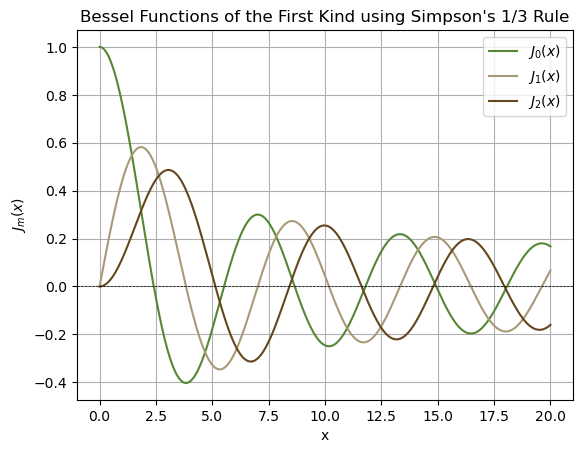

In [15]:
plt.plot(x_20, J(0, x_20), label="$J_{0}(x)$", color="#558734")
plt.plot(x_20, J(1, x_20), label="$J_{1}(x)$", color="#a79a77")
plt.plot(x_20, J(2, x_20), label="$J_{2}(x)$", color="#65461f")
plt.title("Bessel Functions of the First Kind using Simpson's 1/3 Rule")
plt.xlabel("x")
plt.ylabel("$J_m(x)$")
plt.axhline(0, color='black', linewidth=0.5, linestyle='--')
plt.grid(True)

plt.legend()
# plt.savefig("012_Bessel.png")
plt.show()

In [5]:
wavelength = 500e-9
k = (2 * np.pi) / wavelength

# Assuming J_1 is defined as a lambda referencing your J function:
J_1 = lambda x: J(1, x)
#J_2 = lambda x: J(2, x)
#J_3 = lambda x: J(3, x)

def intensityFunc(J_func, r):
    k = (2 * np.pi) / 500e-9
    kr = k * r
    
    # Use np.where to seamlessly protect against 0 division in arrays or scalars
    # If kr == 0, the limit of J1(kr)/kr is 0.5. Otherwise, evaluate normally.
    # Note the critical addition of parentheses around (kr) in the denominator!
    intensity = np.where(kr == 0, 0.5, J_func(kr) / kr) ** 2
    
    return intensity

# Test on extreme cases
# intensityFunc(J_1, 0.5)
# intensityFunc(J_1, 0.0)

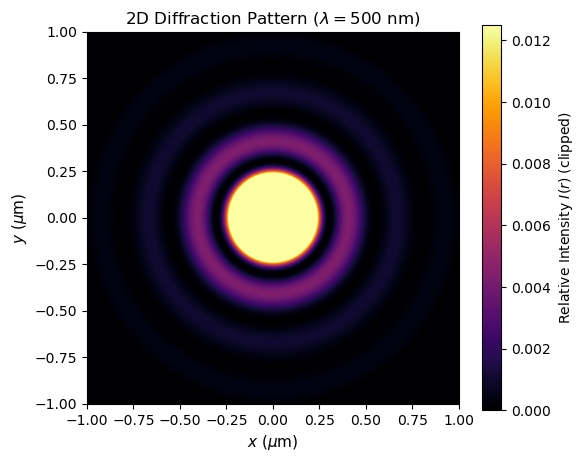

In [16]:
# Plotting Function:
# Did the plot lang, adopt this
r_grid = np.linspace(-1e-6, 1e-6, 500)
intensity1 = intensityFunc(J_1, r_grid)

# Trun into 2D
x = np.linspace(-1e-6, 1e-6, 500)
y = np.linspace(-1e-6, 1e-6, 500)
X, Y = np.meshgrid(x, y)

# Radial distance
R = np.sqrt(X**2 + Y**2)

# Map the 1D radial onto the 2D grid ---
# The pattern depends only on r, so we look up I(r) from the profile computed earlier.
# Points with r beyond the profile's range (the corners) get intensity 0.
intensity_2D = np.interp(R, r_grid, intensity1, right=0)

# Diffraction patttern rendering ---
plt.figure(figsize=(6, 5))
# I searched this one up
plt.imshow(intensity_2D,
           extent=[x[0] * 1e6, x[-1] * 1e6, y[0] * 1e6, y[-1] * 1e6],
           origin='lower',
           cmap='inferno',
           vmax=0.05 * intensity_2D.max())   # clip the bright center so the faint rings show

# Layout Styling
plt.colorbar(label="Relative Intensity $I(r)$ (clipped)")
plt.title("2D Diffraction Pattern ($\\lambda = 500$ nm)", fontsize=12)
plt.xlabel("$x$ ($\\mu$m)", fontsize=11)
plt.ylabel("$y$ ($\\mu$m)", fontsize=11)
plt.gca().set_aspect('equal')
# plt.savefig("012_DiffractionPattern.png")
plt.show()

### Problem 2: Integration via Monte Carlo with Importance sampling

Evaluate the gamma function for $z\in [0,5]$ $$ \Gamma(z) = \int_{0}^{\infty} t^{z-1} e^{-t} \, dt $$. Plot the function using your integration method vs `scipy.special.gamma` (two curves)

Use monte carlo method with importance sampling, by recasting the integral into the form 

$$ \int f(x)dx = \int g(x)p(x)dx, \ \  g(x) = \frac{f(x)}{p(x)}$$



Report discussion: What is the difference between this version of Monte Carlo and the one we did in the previous session? What should we be careful of when applying Monte Carlo with Importance sampling?

In [7]:
# Import this so we can run the scipy.special.gamma
from scipy.special import gamma, factorial
x = np.linspace(0,5,1)

In [8]:
gammaFunc = lambda t, z: (t ** (z - 1)) * np.exp(-t)

In [9]:
# Monte Carlo (Refer to Exercise 11)
def montecarlo(function, upperbound, lowerbound, N):
    rng = np.random.default_rng() # generate random numbers
    xs = rng.uniform(lowerbound,upperbound,N)
    ys = function(xs)
    integral = (upperbound - lowerbound) * np.mean(ys)
    return integral

In [10]:
# Monte Carlo with Importance Sampling
# Instead of sampling uniformly, we sample x from p(x) and average g(x) = f(x)/p(x)
def montecarlo_importance(g, sampler, N):
    xs = sampler(N)          # random numbers drawn from p(x)
    ys = g(xs)               # evaluate g(x) = f(x)/p(x) at those points
    integral = np.mean(ys)   # no (b - a) factor: p(x) is already normalized
    return integral

In [11]:
rng = np.random.default_rng(42)

# p(t) = e^(-t) on [0, inf)  -> exponential distribution, already normalized
expSampler = lambda N: rng.exponential(1.0, N)

# g(t) = f(t)/p(t) = t^(z-1) e^(-t) / e^(-t) = t^(z-1)
gFunc = lambda t, z: t ** (z - 1)

In [12]:
N = 100000
zs = np.linspace(0.1, 5, 50)   # start at 0.1, since Gamma(z) diverges at z = 0

gamma_mc = []
for z in zs:
    g = lambda t: gFunc(t, z)
    gamma_mc.append(montecarlo_importance(g, expSampler, N))
gamma_mc = np.array(gamma_mc)

gamma_scipy = gamma(zs)

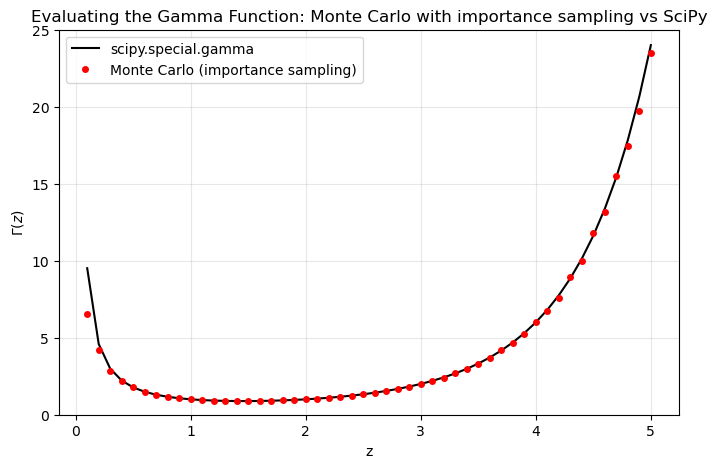

In [17]:
plt.figure(figsize=(8, 5))
plt.plot(zs, gamma_scipy, 'k-', label='scipy.special.gamma')
plt.plot(zs, gamma_mc, 'ro', markersize=4, label='Monte Carlo (importance sampling)')
plt.xlabel('z')
plt.ylabel(r'$\Gamma(z)$')
plt.title(r'Evaluating the Gamma Function: Monte Carlo with importance sampling vs SciPy')
plt.ylim(0, 25)
plt.legend()
plt.grid(alpha=0.3)
plt.savefig("012_GammaFunction.png")
plt.show()

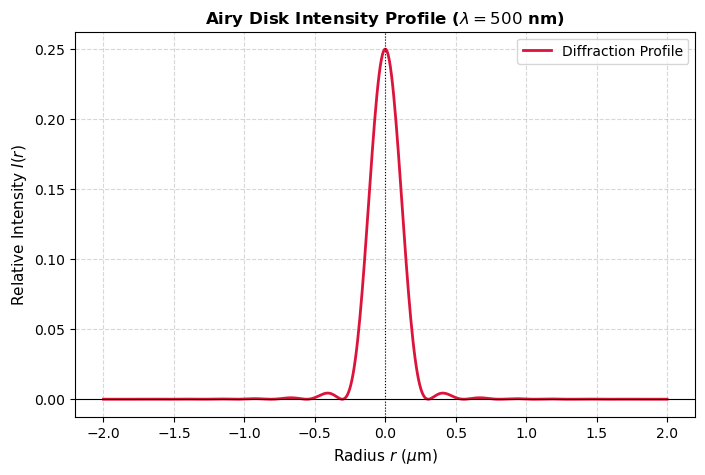

In [14]:
# Not needed, pero I'll just put
# --- PLOTTING ENVIRONMENT ---

# Generate a fine micro-scale radius grid (from -2 to +2 micrometers)
# This captures the beautiful diffraction rings/peaks perfectly
r_grid = np.linspace(-2e-6, 2e-6, 500)
calculated_intensity = intensityFunc(J_1, r_grid)

# Plotting layout
plt.figure(figsize=(8, 5))
plt.plot(r_grid * 1e6, calculated_intensity, color='crimson', linewidth=2, label='Diffraction Profile')

# Layout Styling
plt.title("Airy Disk Intensity Profile ($\\lambda = 500$ nm)", fontsize=12, fontweight='bold')
plt.xlabel("Radius $r$ ($\\mu$m)", fontsize=11)
plt.ylabel("Relative Intensity $I(r)$", fontsize=11)
plt.grid(True, linestyle='--', alpha=0.5)
plt.axhline(0, color='black', linewidth=0.8)
plt.axvline(0, color='black', linewidth=0.8, linestyle=':')
plt.legend()

plt.show()